In [35]:
# %pip install pandas numpy matplotlib scipy seaborn scikit-learn 
# DATA ANALYTICS - LIBRARY IMPORTS

# Data manipulation and analysis
import pandas as pd
# pd: Load CSV/Excel files, clean data, filter rows,
# join tables, group data, and handle missing values.

# Numerical computing
import numpy as np
# np: Arrays, mathematical operations, statistical
# calculations, and numerical transformations.

# Data visualization
import matplotlib
import matplotlib.pyplot as plt
# plt: Create line charts, bar charts, histograms,
# scatter plots, and customize chart layouts.

# Scientific and statistical computing
import scipy
# scipy: Statistical tests, probability distributions,
# optimization, and scientific calculations.
import scipy.stats as scipy_stats
# Statistical data visualization
import seaborn as sns
# sns: Statistical charts, heatmaps, boxplots,
# distributions, and correlation visualizations.

# Machine learning
import sklearn
# sklearn: Data preprocessing, feature engineering,
# model training, model selection, and evaluation.

# Statistical modeling and inference
import statsmodels as sm

# File and directory paths
from pathlib import Path
# Path: Manage file paths across operating systems.

In [36]:
# Verify the installed library versions
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("SciPy version:", scipy.__version__)
print("Matplotlib version:", matplotlib.__version__)
print("Seaborn version:", sns.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Statsmodels version:", sm.__version__)

# pathlib is part of Python's standard library;
# it does not have a package version attribute like these libraries.
print("Path class imported:", Path)


Pandas version: 3.0.3
NumPy version: 2.4.6
SciPy version: 1.17.1
Matplotlib version: 3.11.0
Seaborn version: 0.13.2
Scikit-learn version: 1.9.0
Statsmodels version: 0.14.6
Path class imported: <class 'pathlib.Path'>


In [37]:
# create a datframe of the csv file
df = pd.read_csv(r"C:\Users\vasav\OneDrive\Desktop\DA_PROJECTS\Project_2\Online Retail DATA ANALYTICS - Copy.csv")

In [38]:
# To check how many rows and columns
print("Number of rows and columns:", df.shape)

Number of rows and columns: (541909, 8)


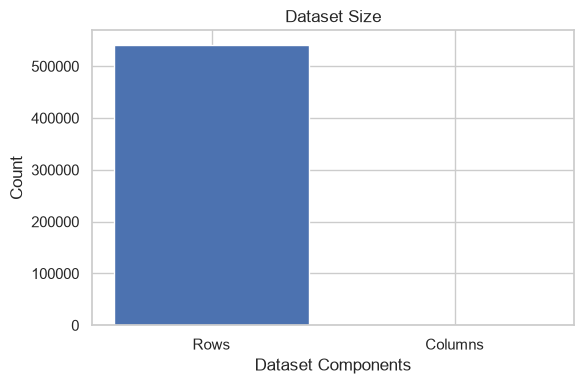

In [39]:
# Get the number of rows and columns
total_rows, total_columns = df.shape

# Create a bar chart
plt.figure(figsize=(6, 4))
plt.bar(
    ["Rows", "Columns"],
    [total_rows, total_columns]
)

plt.title("Dataset Size")
plt.ylabel("Count")
plt.xlabel("Dataset Components")
plt.tight_layout()
plt.show()

In [40]:
# To Print Columns Name
print("The columns names are :-", df.columns.tolist())

The columns names are :- ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [41]:
# To check DataTypes and Non-null Count
print("Info about the df", df.info())

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.8 MB
Info about the df None


In [42]:
# Convert InvoiceDate from string to datetime
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

# Check data type
print(df["InvoiceDate"].dtype)

# Display date and time
display(df[["InvoiceDate"]].head())

# Check missing values
print("Missing dates:", df["InvoiceDate"].isna().sum())

datetime64[us]


,InvoiceDate
0,2010-12-01 08:26:00
1,2010-12-01 08:26:00
2,2010-12-01 08:26:00
3,2010-12-01 08:26:00
4,2010-12-01 08:26:00


Missing dates: 0


In [43]:
# for the particular columns
Count_null = df["CustomerID"].isna().sum()
print("Total null count ", Count_null)

Total null count  135080


In [44]:
# Count the null and its percentage using function
def null_summary(series):
    #count the nulls in series
    count_null = series.isnull().sum()
    #calculate percentage of null values in series
    null_percentage = (
    (count_null / len(series)) * 100 
     if len(series) > 0 else 0
    )
    #calculate not null 
    count_notnull = series.notna().sum()
    #calculate percentage of not null values in series
    notnull_percentage = (
    (count_notnull / len(series)) * 100 
     if len(series) > 0 else 0
    )
    return pd.Series({
    "Total null count is" : count_null,
    "Percentage of null is" : round(null_percentage, 2),
    "Total not null count is" : count_notnull,
    "Percentage of not null is" : round(notnull_percentage, 2)
    })

In [45]:
#apply the null_summary for every columns
null_apply = df.apply(null_summary)
#transform the each columns to row 
null_apply = null_apply.T
#display the null summary 
display(null_apply)

,Total null count is,Percentage of null is,Total not null count is,Percentage of not null is
InvoiceNo,0.0,0.00,541909.0,100.00
StockCode,0.0,0.00,541909.0,100.00
Description,1454.0,0.27,540455.0,99.73
Quantity,0.0,0.00,541909.0,100.00
InvoiceDate,0.0,0.00,541909.0,100.00
UnitPrice,0.0,0.00,541909.0,100.00
CustomerID,135080.0,24.93,406829.0,75.07
Country,0.0,0.00,541909.0,100.00


In [46]:
#total null and it's percentage
total_nulls = df.isna().sum().sum()
total_nulls_percentage = ((total_nulls / df.size * 100))
print("total null values in cells -----> ",total_nulls)
print("total null values in cells percentage-----> ",total_nulls_percentage)

total null values in cells ----->  136534
total null values in cells percentage----->  3.149375633178264


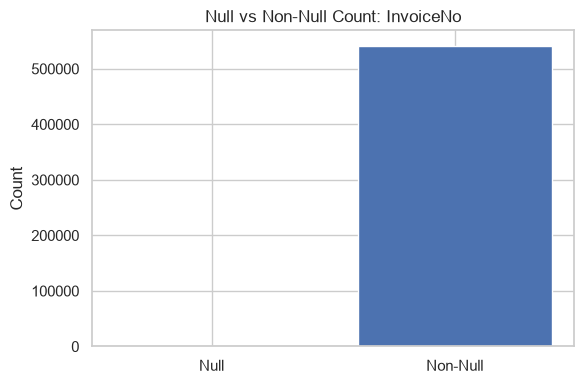

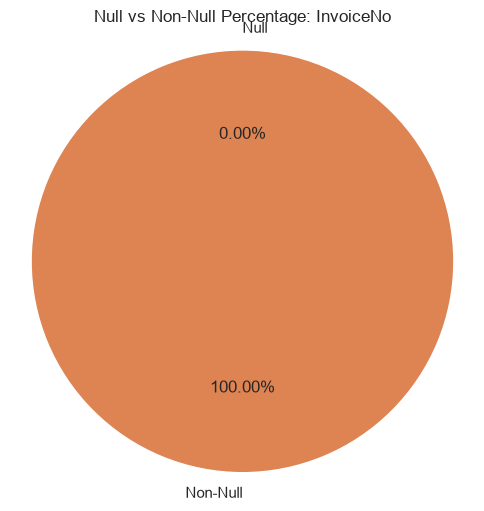

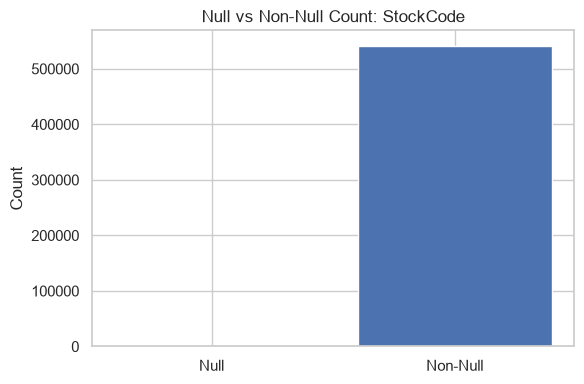

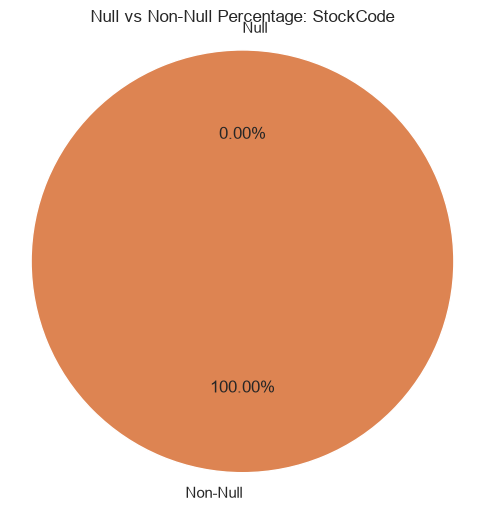

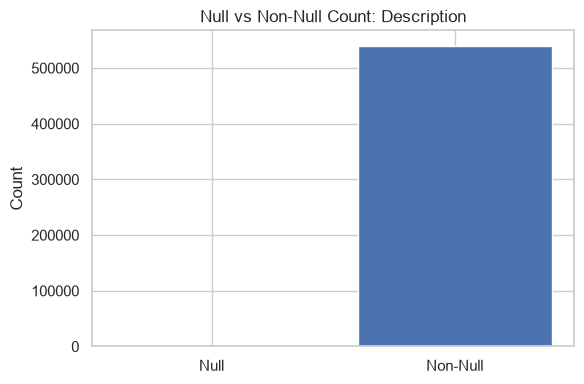

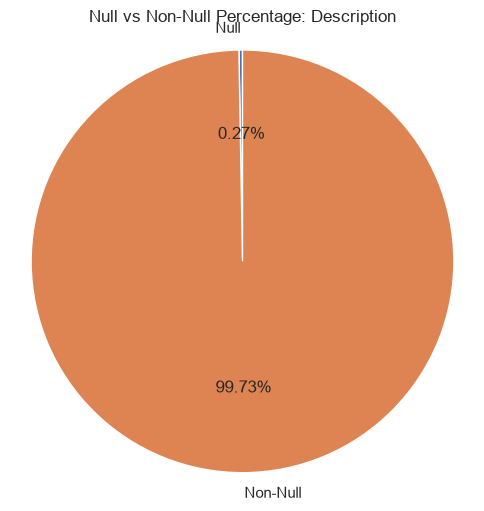

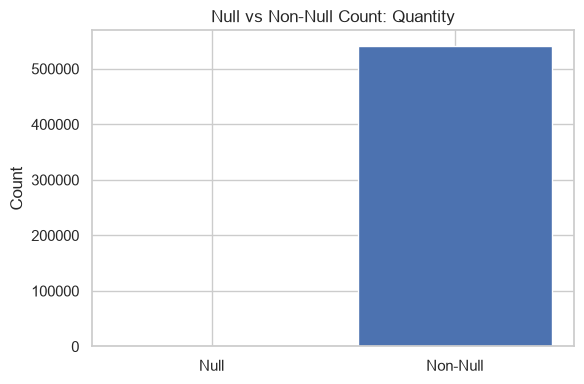

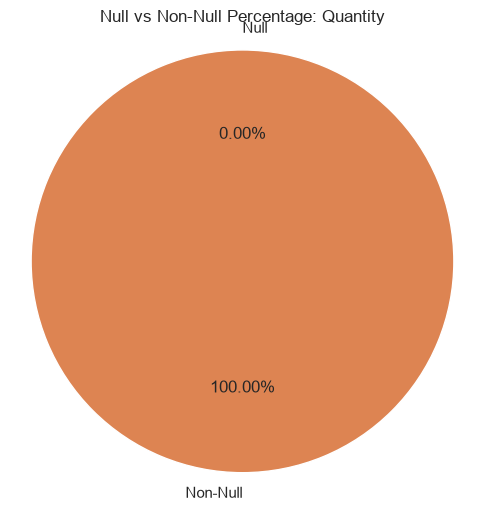

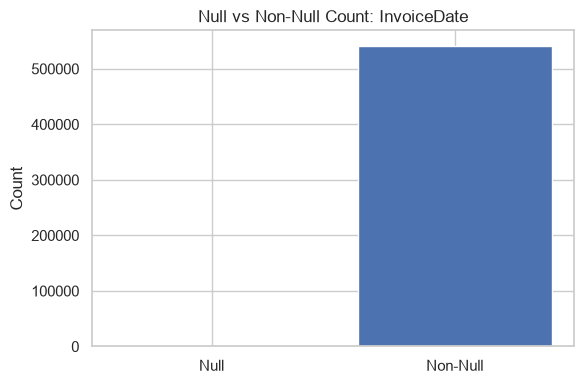

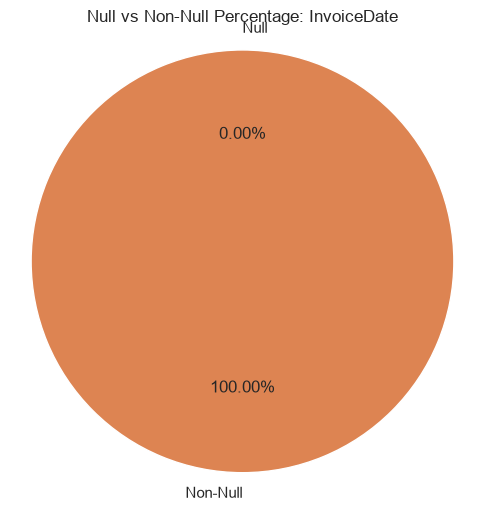

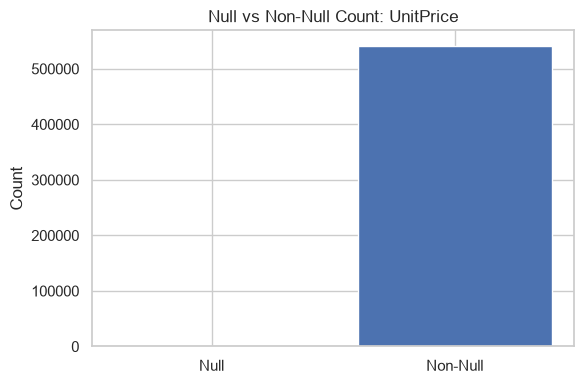

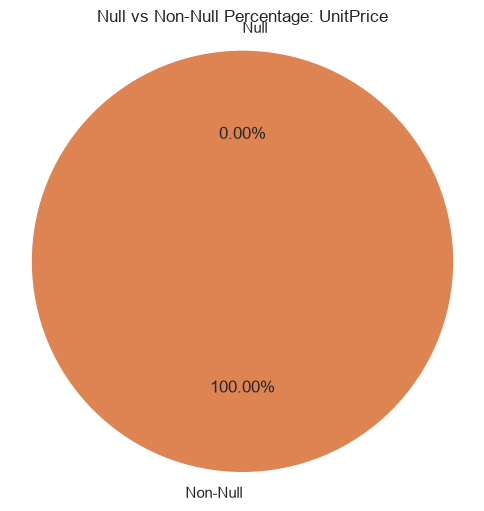

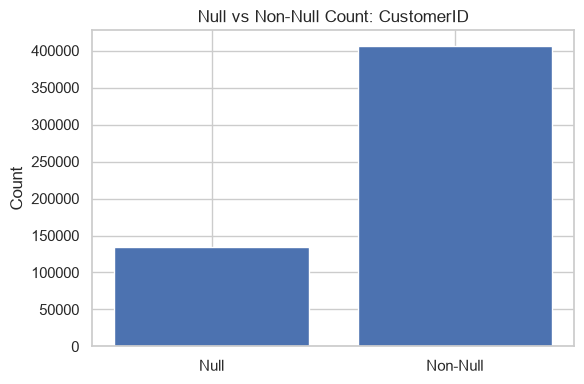

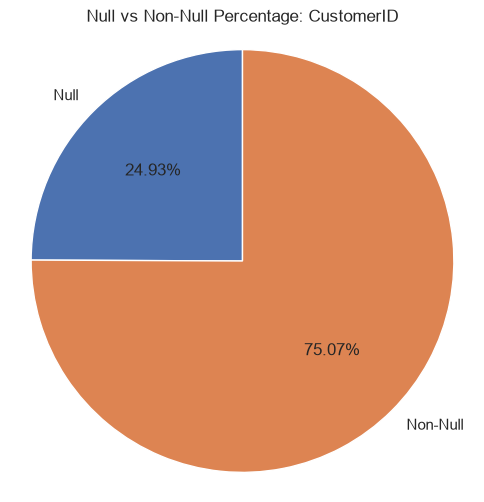

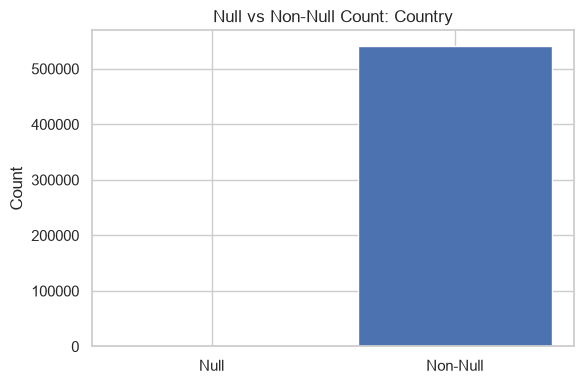

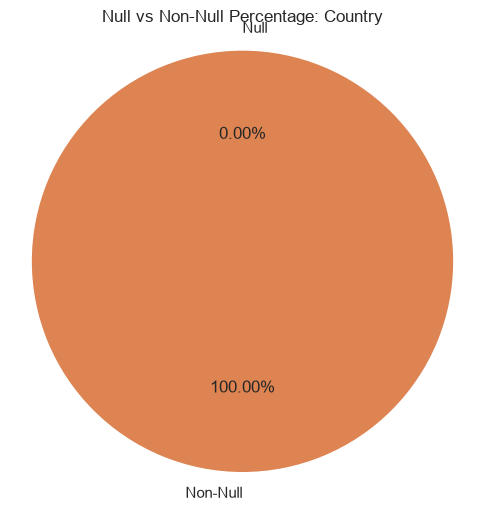

In [47]:
#chart using matplotlib.pyplot as plt
# Apply the null analysis function to every column
null_apply = df.apply(null_summary).T

# Rename columns to standard names
null_apply.columns = [
    "Null_Count",
    "Null_Percentage",
    "Non_Null_Count",
    "Non_Null_Percentage"
]

# Loop through every column and create its charts
for column in null_apply.index:

    # Get null and non-null counts for this column
    null_count = null_apply.loc[column, "Null_Count"]
    non_null_count = null_apply.loc[column, "Non_Null_Count"]

    # Get null and non-null percentages for this column
    null_percentage = null_apply.loc[column, "Null_Percentage"]
    non_null_percentage = null_apply.loc[column, "Non_Null_Percentage"]
    
    # CHART 1: BAR CHART - COUNTS-
    plt.figure(figsize=(6, 4))

    plt.bar(
        ["Null", "Non-Null"],
        [null_count, non_null_count]
    )

    plt.title(f"Null vs Non-Null Count: {column}")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

    # CHART 2: PIE CHART - PERCENTAGES

    plt.figure(figsize=(6, 6))

    if null_count + non_null_count == 0:
        # Handle an empty Series without dividing by zero
        plt.title(f"No Data Available: {column}")
        plt.axis("off")
    else:
        plt.pie(
            [null_percentage, non_null_percentage],
            labels=["Null", "Non-Null"],
            autopct="%1.2f%%",
            startangle=90
        )

        plt.title(f"Null vs Non-Null Percentage: {column}")
        plt.axis("equal")

    plt.show()


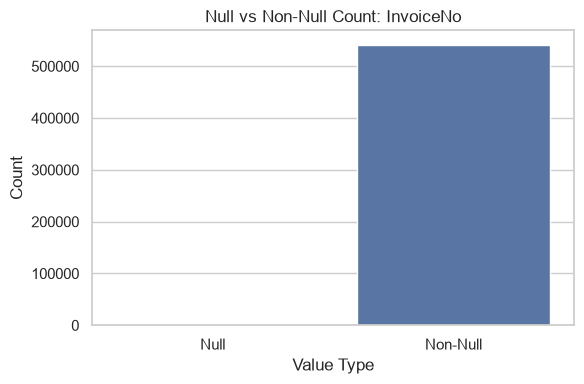

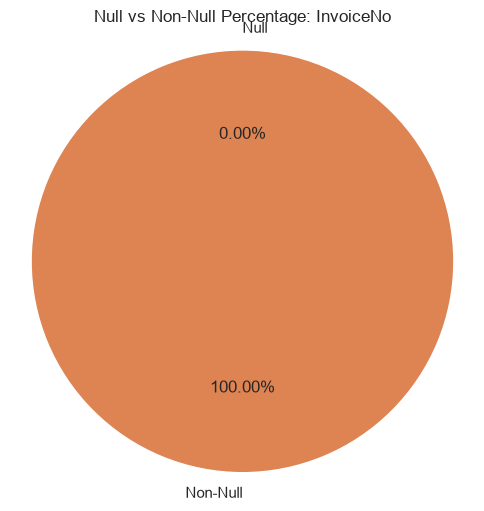

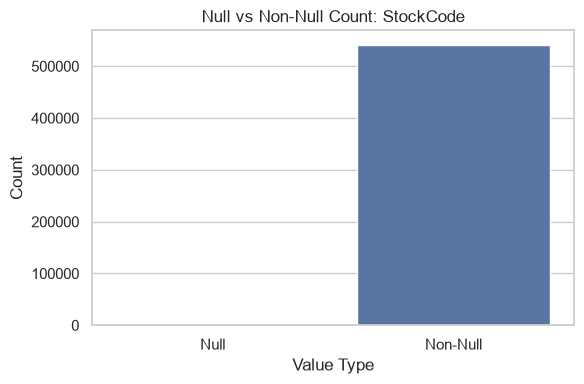

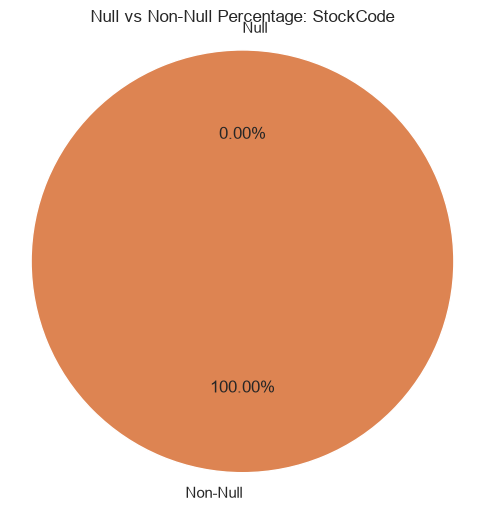

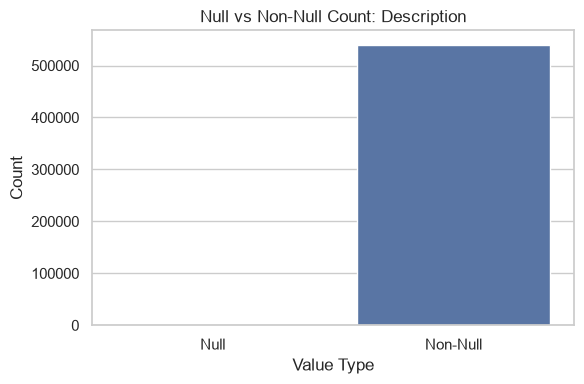

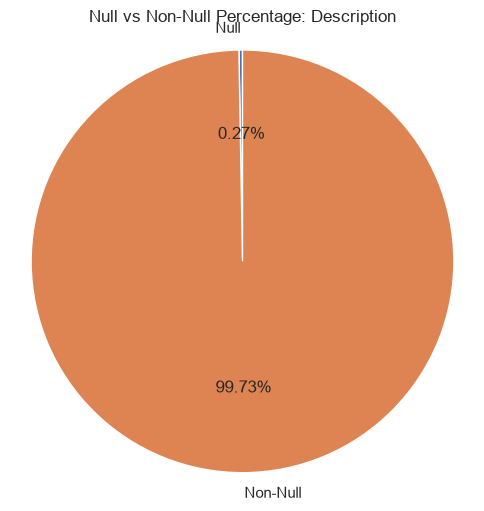

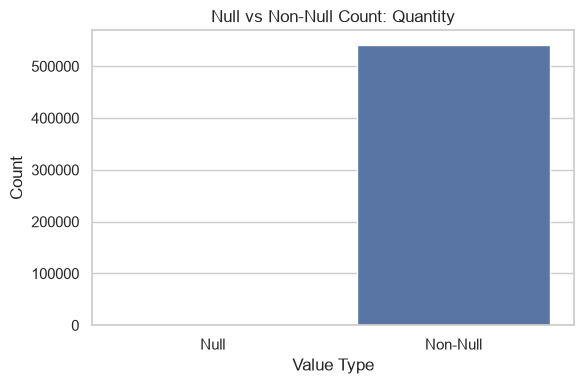

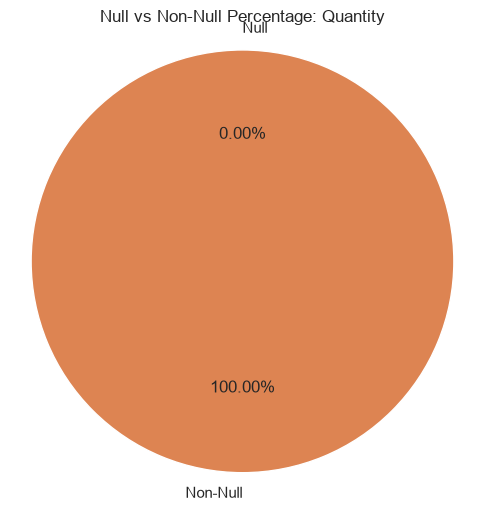

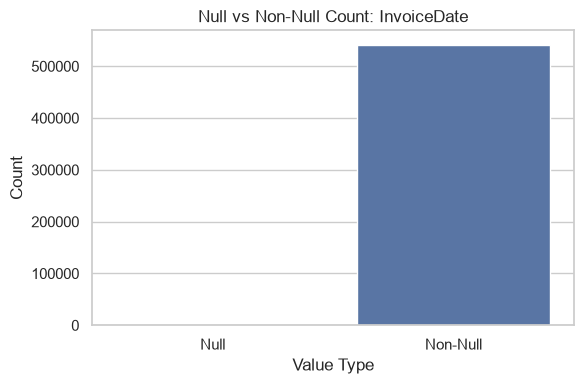

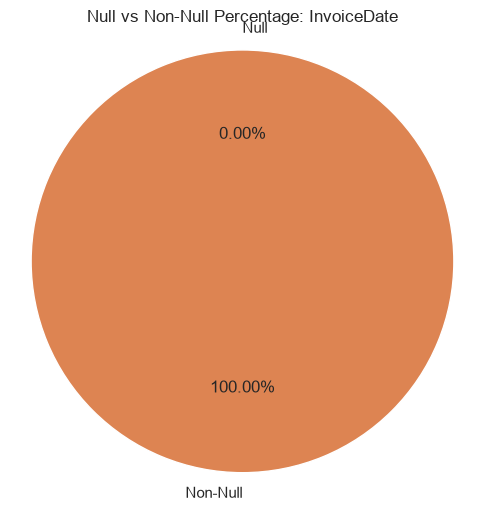

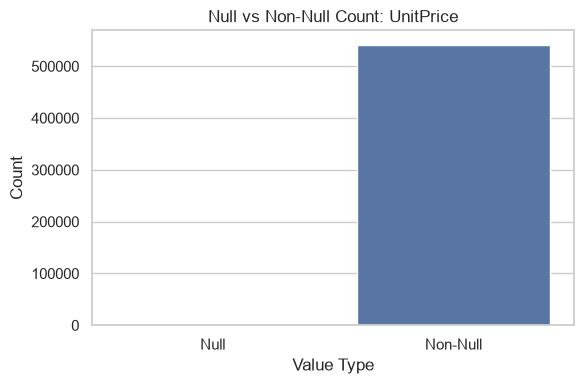

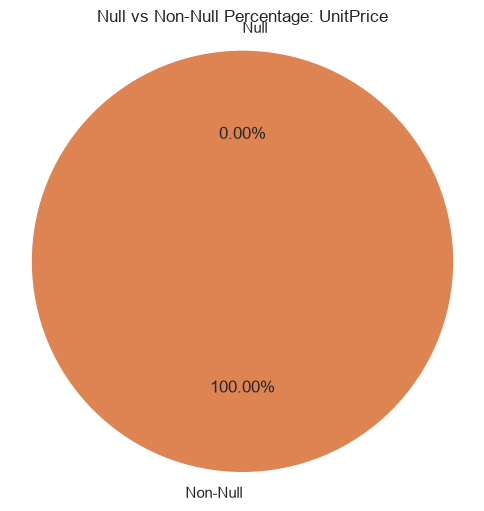

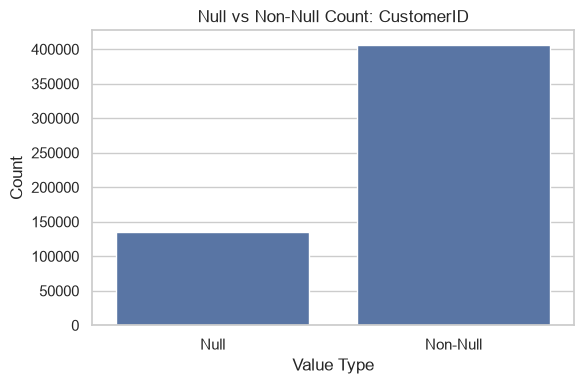

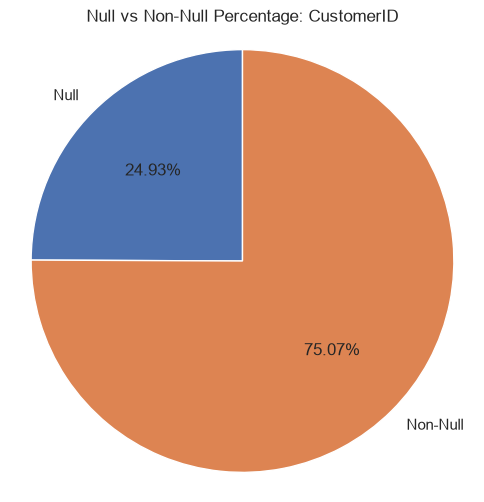

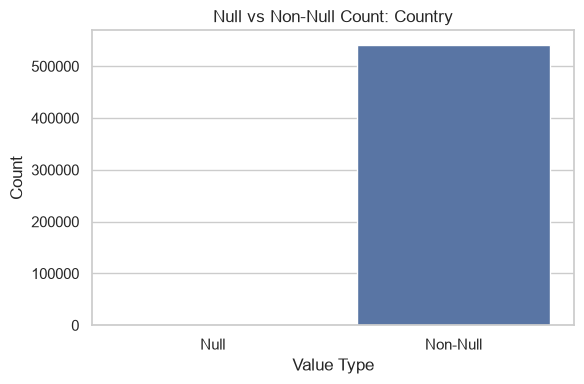

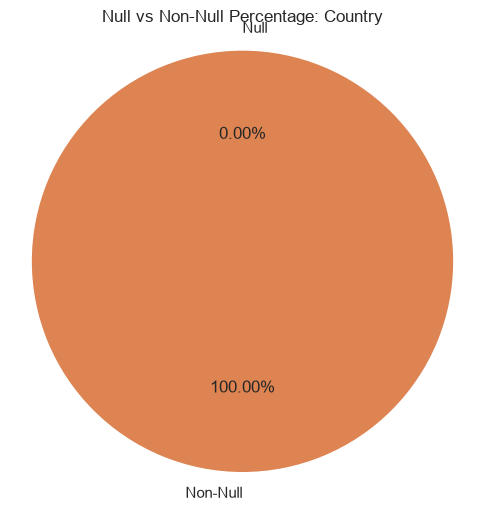

In [48]:
# Set the Seaborn chart theme
sns.set_theme(style="whitegrid")

# Apply null analysis to every DataFrame column
null_apply = df.apply(null_summary).T

# Rename columns for consistency
null_apply.columns = [
    "Null_Count",
    "Null_Percentage",
    "Non_Null_Count",
    "Non_Null_Percentage"
]

# Loop through every column
for column in null_apply.index:

    # Extract null and non-null counts
    null_count = null_apply.loc[column, "Null_Count"]
    non_null_count = null_apply.loc[column, "Non_Null_Count"]

    # Extract null and non-null percentages
    null_percentage = null_apply.loc[column, "Null_Percentage"]
    non_null_percentage = null_apply.loc[column, "Non_Null_Percentage"]

    # Prepare data for plotting
    chart_data = pd.DataFrame({
        "Value_Type": ["Null", "Non-Null"],
        "Count": [null_count, non_null_count]
    })

    # CHART 1: SEABORN BAR CHART

    plt.figure(figsize=(6, 4))

    sns.barplot(
        data=chart_data,
        x="Value_Type",
        y="Count"
    )

    plt.title(f"Null vs Non-Null Count: {column}")
    plt.xlabel("Value Type")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

    # CHART 2: PIE CHART
    # Matplotlib is required for this chart
    if null_count + non_null_count > 0:

        plt.figure(figsize=(6, 6))

        plt.pie(
            [null_percentage, non_null_percentage],
            labels=["Null", "Non-Null"],
            autopct="%1.2f%%",
            startangle=90
        )

        plt.title(f"Null vs Non-Null Percentage: {column}")
        plt.axis("equal")
        plt.show()


In [49]:
#for particular columns data view of top 
df['Country'].head(100)

0     United Kingdom
1     United Kingdom
2     United Kingdom
3     United Kingdom
4     United Kingdom
           ...      
95    United Kingdom
96    United Kingdom
97    United Kingdom
98    United Kingdom
99    United Kingdom
Name: Country, Length: 100, dtype: str

In [50]:
#for particular columns data view of bottom
df['Country'].tail(100)

541809    United Kingdom
541810    United Kingdom
541811    United Kingdom
541812    United Kingdom
541813    United Kingdom
               ...      
541904            France
541905            France
541906            France
541907            France
541908            France
Name: Country, Length: 100, dtype: str

In [51]:
#function to view top 500, middle 500 and bottom 500 
def view_500(series):
    print(f"Column name is : {series.name}")
    #view top 500 raws
    display(series.head(500))
    #view  middle 500 raws
    middle_position = max(0, (len(series) // 2) - 500)
    display(series.iloc[middle_position : middle_position + 500])
    #view bottom 500 values
    display(series.tail(500))

In [52]:
#applying function to all columns 
for columns in df.columns:
    view_500(df[columns])

Column name is : InvoiceNo


0      536365
1      536365
2      536365
3      536365
4      536365
        ...  
495    536409
496    536409
497    536409
498    536409
499    536409
Name: InvoiceNo, Length: 500, dtype: str

270454    560568
270455    560568
270456    560568
270457    560568
270458    560568
           ...  
270949    560601
270950    560601
270951    560601
270952    560601
270953    560601
Name: InvoiceNo, Length: 500, dtype: str

541409    581498
541410    581498
541411    581498
541412    581498
541413    581498
           ...  
541904    581587
541905    581587
541906    581587
541907    581587
541908    581587
Name: InvoiceNo, Length: 500, dtype: str

Column name is : StockCode


...

541409        NaN
541410        NaN
541411        NaN
541412        NaN
541413        NaN
           ...   
541904    12680.0
541905    12680.0
541906    12680.0
541907    12680.0
541908    12680.0
Name: CustomerID, Length: 500, dtype: float64

Column name is : Country


0      United Kingdom
1      United Kingdom
2      United Kingdom
3      United Kingdom
4      United Kingdom
            ...      
495    United Kingdom
496    United Kingdom
497    United Kingdom
498    United Kingdom
499    United Kingdom
Name: Country, Length: 500, dtype: str

270454    United Kingdom
270455    United Kingdom
270456    United Kingdom
270457    United Kingdom
270458    United Kingdom
               ...      
270949    United Kingdom
270950    United Kingdom
270951    United Kingdom
270952    United Kingdom
270953    United Kingdom
Name: Country, Length: 500, dtype: str

541409    United Kingdom
541410    United Kingdom
541411    United Kingdom
541412    United Kingdom
541413    United Kingdom
               ...      
541904            France
541905            France
541906            France
541907            France
541908            France
Name: Country, Length: 500, dtype: str

In [53]:
#to fet the count of the uniue values 
def unique_value(series):
    display(series.nunique())
unique_value(df["Country"])

38

In [54]:
#to view the unique value for one series 
df.Country.unique()

<ArrowStringArray>
[      'United Kingdom',               'France',            'Australia',
          'Netherlands',              'Germany',               'Norway',
                 'EIRE',          'Switzerland',                'Spain',
               'Poland',             'Portugal',                'Italy',
              'Belgium',            'Lithuania',                'Japan',
              'Iceland',      'Channel Islands',              'Denmark',
               'Cyprus',               'Sweden',              'Austria',
               'Israel',              'Finland',              'Bahrain',
               'Greece',            'Hong Kong',            'Singapore',
              'Lebanon', 'United Arab Emirates',         'Saudi Arabia',
       'Czech Republic',               'Canada',          'Unspecified',
               'Brazil',                  'USA',   'European Community',
                'Malta',                  'RSA']
Length: 38, dtype: str

In [55]:
#to view the unique values and it's count function
def unique_value_count(series):
    print("The unique_values and its counts -----> ", series.value_counts())
    print("No count of unique_values -----> ",series.nunique())
for Column in df.columns:
    unique_value_count(df[Column])

The unique_values and its counts ----->  InvoiceNo
573585     1114
581219      749
581492      731
580729      721
558475      705
           ... 
581487        1
581491        1
C581499       1
581566        1
C581568       1
Name: count, Length: 25900, dtype: int64
No count of unique_values ----->  25900
The unique_values and its counts ----->  StockCode
85123A    2313
22423     2203
85099B    2159
47566     1727
20725     1639
          ... 
23609        1
85179a       1
23617        1
90214U       1
47591b       1
Name: count, Length: 4070, dtype: int64
No count of unique_values ----->  4070
The unique_values and its counts ----->  Description
WHITE HANGING HEART T-LIGHT HOLDER    2369
REGENCY CAKESTAND 3 TIER              2200
JUMBO BAG RED RETROSPOT               2159
PARTY BUNTING                         1727
LUNCH BAG RED RETROSPOT               1638
                                      ... 
LETTER "U" BLING KEY RING                1
wet                                      1


In [56]:
# duplicated count and in percentage 
def duplicated_count(series):
    print("The exact duplicated count", series.duplicated().sum())
    print("The percentage of duplicated", (series.duplicated().sum() / len(df)) * 100) 
# for Columns_1 in df.columns:
# duplicated_count(df[Columns_1])
duplicated_count(df)
# Count the null and its percentage using function
def null_summary(series):
    #count the nulls in series
    count_null = series.isnull().sum()
    #calculate percentage of null values in series
    null_percentage = (
    (count_null / len(series)) * 100 
     if len(series) > 0 else 0
    )
    #calculate not null 
    count_notnull = series.notna().sum()
    #calculate percentage of not null values in series
    notnull_percentage = (
    (count_notnull / len(series)) * 100 
     if len(series) > 0 else 0
    )
    return pd.Series({
    "Total null count is" : count_null,
    "Percentage of null is" : round(null_percentage, 2),
    "Total not null count is" : count_notnull,
    "Percentage of not null is" : round(notnull_percentage, 2)
    })
    

The exact duplicated count 5268
The percentage of duplicated 0.9721189350979592


In [57]:
def duplicated_records(series):
    display(series[series.duplicated()])
duplicated_records(df)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
...,...,...,...,...,...,...,...,...
541675,581538,22068,BLACK PIRATE TREASURE CHEST,1,2011-12-09 11:34:00,0.39,14446.0,United Kingdom
541689,581538,23318,BOX OF 6 MINI VINTAGE CRACKERS,1,2011-12-09 11:34:00,2.49,14446.0,United Kingdom
541692,581538,22992,REVOLVER WOODEN RULER,1,2011-12-09 11:34:00,1.95,14446.0,United Kingdom
541699,581538,22694,WICKER STAR,1,2011-12-09 11:34:00,2.10,14446.0,United Kingdom


In [58]:
# FUNCTION: VIEW EXACT DUPLICATE PAIRS SIDE-BY-SIDE
def duplicated_count(data_obj):
    
    # 1. Count only the extra copies (how many rows would be removed on drop_duplicates)
    extra_dup_count = data_obj.duplicated(keep="first").sum()
    extra_dup_pct = (extra_dup_count / len(data_obj)) * 100 if len(data_obj) > 0 else 0
    
    # 2. Count all rows involved in duplicates (Original row + Duplicate copy)
    all_involved_count = data_obj.duplicated(keep=False).sum()
    
    print("Extra duplicate copies count (keep='first') -----> ", extra_dup_count)
    print("Percentage of extra duplicate copies        -----> ", round(extra_dup_pct, 2), "%")
    print("Total rows in duplicate pairs (keep=False)  -----> ", all_involved_count)
    
    # 3. Extract BOTH the original row and its exact duplicate copy (keep=False)
    duplicate_pairs = data_obj[data_obj.duplicated(keep=False)]
    
    # 4. Sort so identical rows sit directly above/below each other
    if isinstance(data_obj, pd.DataFrame):
        duplicate_pairs = duplicate_pairs.sort_values(by=list(data_obj.columns))
    else:
        duplicate_pairs = duplicate_pairs.sort_values()
        
    print("\n--- EXACT DUPLICATE ROWS (ORIGINAL + COPY SIDE-BY-SIDE) ---")
    display(duplicate_pairs.head(10))
    display(duplicate_pairs.tail(10))
    # display(duplicate_pairs)
# Run on the entire DataFrame
duplicated_count(df)

Extra duplicate copies count (keep='first') ----->  5268
Percentage of extra duplicate copies        ----->  0.97 %
Total rows in duplicate pairs (keep=False)  ----->  10147

--- EXACT DUPLICATE ROWS (ORIGINAL + COPY SIDE-BY-SIDE) ---


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
598,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
411643,C572226,85066,CREAM SWEETHEART MINI CHEST,-1,2011-10-21 13:58:00,12.75,15321.0,United Kingdom
411644,C572226,85066,CREAM SWEETHEART MINI CHEST,-1,2011-10-21 13:58:00,12.75,15321.0,United Kingdom
436250,C574095,22326,ROUND SNACK BOXES SET OF4 WOODLAND,-1,2011-11-03 09:54:00,2.95,12674.0,France
436251,C574095,22326,ROUND SNACK BOXES SET OF4 WOODLAND,-1,2011-11-03 09:54:00,2.95,12674.0,France
440148,C574510,22360,GLASS JAR ENGLISH CONFECTIONERY,-1,2011-11-04 13:25:00,2.95,15110.0,United Kingdom
440149,C574510,22360,GLASS JAR ENGLISH CONFECTIONERY,-1,2011-11-04 13:25:00,2.95,15110.0,United Kingdom
461407,C575940,23309,SET OF 60 I LOVE LONDON CAKE CASES,-24,2011-11-13 11:38:00,0.55,17838.0,United Kingdom
461408,C575940,23309,SET OF 60 I LOVE LONDON CAKE CASES,-24,2011-11-13 11:38:00,0.55,17838.0,United Kingdom
529980,C580764,22667,RECIPE BOX RETROSPOT,-12,2011-12-06 10:38:00,2.95,14562.0,United Kingdom
529981,C580764,22667,RECIPE BOX RETROSPOT,-12,2011-12-06 10:38:00,2.95,14562.0,United Kingdom


In [59]:
#simple statistical disctiption without the drop na, without standardize and without replacement of mean, median, mean
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [60]:
#make copy of existing df for the calculation
df_1 = df.copy()

In [61]:
# FUNCTION TO TRIM AND CONVERT TO PROPER CASE
# FOR EVERY COLUMN IN A DATAFRAME
def trim_proper(dataframe):
    dataframe = dataframe.apply(
        lambda series: series.apply(
            lambda x: x.strip().title()
            if isinstance(x, str) else x
        )
    )
    return dataframe


# Apply the function to df_1
df_1 = trim_proper(df_1)


# Verify the results
print(df_1.head())
print(df_1.info())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   White Hanging Heart T-Light Holder         6   
1    536365     71053                  White Metal Lantern         6   
2    536365    84406B       Cream Cupid Hearts Coat Hanger         8   
3    536365    84029G  Knitted Union Flag Hot Water Bottle         6   
4    536365    84029E       Red Woolly Hottie White Heart.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----

In [62]:
# DROP DUPLICATES, HANDLE NULL CUSTOMER_ID

# Step 1: Drop duplicate rows
df_1 = df_1.drop_duplicates()

# Step 2: Replace null Customer_ID values with "X"
df_1['CustomerID'] = df_1['CustomerID'].fillna("X")

# Step 2.1: Replace null description values with "X"
df_1['Description'] = df_1['Description'].fillna("X")
# Step 3: Verify the results
print("Duplicate Rows:", df_1.duplicated().sum())

print("\nNull Values in Customer_ID:")
print(df_1['CustomerID'].isnull().sum())

print("\nTotal Null Values in Each Column:")
print(df_1.isnull().sum())

print("\nFinal DataFrame Shape:")
print(df_1.shape)
df_1.info()

Duplicate Rows: 0

Null Values in Customer_ID:
0

Total Null Values in Each Column:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

Final DataFrame Shape:
(536641, 8)
<class 'pandas.DataFrame'>
Index: 536641 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    536641 non-null  str           
 1   StockCode    536641 non-null  str           
 2   Description  536641 non-null  str           
 3   Quantity     536641 non-null  int64         
 4   InvoiceDate  536641 non-null  datetime64[us]
 5   UnitPrice    536641 non-null  float64       
 6   CustomerID   536641 non-null  object        
 7   Country      536641 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(1), object(1), str(4)
memory usage: 63.1+ MB


In [63]:
#devide the numeric nad categorical value 
# devide numeric and categorical columns
# SEPARATE ALL DATAFRAME COLUMNS BY DATA TYPE

# 1. Numeric types: integers, floats, complex numbers, etc.
numeric_columns = df_1.select_dtypes(
    include=["number"]
).columns.tolist()

# 2. Categorical types: text, categories, strings, Boolean values
categorical_columns = df_1.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

# 3. Date and time types
datetime_columns = df_1.select_dtypes(
    include=["datetime", "datetimetz"]
).columns.tolist()

# 4. Time duration types
timedelta_columns = df_1.select_dtypes(
    include=["timedelta"]
).columns.tolist()

# 5. Any remaining or uncommon data types
classified_columns = (
    numeric_columns
    + categorical_columns
    + datetime_columns
    + timedelta_columns
)

other_columns = [
    column for column in df_1.columns
    if column not in classified_columns
]

# DISPLAY ALL COLUMN GROUPS

print("Numeric Columns:", numeric_columns)
print("\nCategorical Columns:", categorical_columns)
print("\nDate/Time Columns:", datetime_columns)
print("\nTime Duration Columns:", timedelta_columns)
print("\nOther Columns:", other_columns)

# VERIFY THAT NO COLUMN WAS OMITTED

print("\nTotal DataFrame Columns:", len(df_1.columns))
print("Total Classified Columns:", len(classified_columns) + len(other_columns))
print("All Columns Accounted For:",
      set(df_1.columns) ==
      set(classified_columns + other_columns))

Numeric Columns: ['Quantity', 'UnitPrice']

Categorical Columns: ['InvoiceNo', 'StockCode', 'Description', 'CustomerID', 'Country']

Date/Time Columns: ['InvoiceDate']

Time Duration Columns: []

Other Columns: []

Total DataFrame Columns: 8
Total Classified Columns: 8
All Columns Accounted For: True


In [64]:
# 1. FUNCTION TO FIND MEAN, MEDIAN AND MODE
def mean_median_mode(series):
    mean_value = round(series.mean(), 5)
    median_value = round(series.median(), 5)

    mode_value = [
        round(value, 5)
        for value in series.mode().tolist()
    ]

    return mean_value, median_value, mode_value

# 2. FUNCTION TO FIND MIN, MAX, RANGE AND COEFFICIENT OF RANGE

def min_max_range(series):
    min_value = round(series.min(), 5)
    max_value = round(series.max(), 5)

    range_value = round(max_value - min_value, 5)

    denominator = max_value + min_value

    coefficient_range = (
        round(range_value / denominator, 5)
        if denominator != 0
        else np.nan
    )

    return min_value, max_value, range_value, coefficient_range

# 3. FUNCTION TO FIND PERCENTILES
def percentiles(series):
    p01 = round(series.quantile(0.01), 5)
    p05 = round(series.quantile(0.05), 5)
    p10 = round(series.quantile(0.10), 5)
    p20 = round(series.quantile(0.20), 5)
    p25 = round(series.quantile(0.25), 5)
    p30 = round(series.quantile(0.30), 5)
    p40 = round(series.quantile(0.40), 5)
    p50 = round(series.quantile(0.50), 5)
    p60 = round(series.quantile(0.60), 5)
    p70 = round(series.quantile(0.70), 5)
    p75 = round(series.quantile(0.75), 5)
    p80 = round(series.quantile(0.80), 5)
    p90 = round(series.quantile(0.90), 5)
    p95 = round(series.quantile(0.95), 5)
    p99 = round(series.quantile(0.99), 5)

    return (
        p01, p05, p10, p20, p25, p30, p40, p50,
        p60, p70, p75, p80, p90, p95, p99
    )

# 4. FUNCTION TO FIND QUARTILES, IQR, QD AND CQD

def quartiles_iqr_qd_cqd(series):
    q1 = round(series.quantile(0.25), 5)
    q2 = round(series.quantile(0.50), 5)
    q3 = round(series.quantile(0.75), 5)

    # Interquartile Range
    iqr = round(q3 - q1, 5)

    # Quartile Deviation
    qd = round(iqr / 2, 5)

    # Coefficient of Quartile Deviation
    denominator = q3 + q1

    cqd = (
        round(iqr / denominator, 5)
        if denominator != 0
        else np.nan
    )

    return q1, q2, q3, iqr, qd, cqd

# 5. FUNCTION TO FIND ABSOLUTE DEVIATIONS
def absolute_deviations(series):
    mean_value = series.mean()
    median_value = series.median()

    # Mean Absolute Deviation about the mean
    mean_absolute_deviation = round(
        (series - mean_value).abs().mean(), 5
    )

    # Median Absolute Deviation about the median
    median_absolute_deviation = round(
        (series - median_value).abs().median(), 5
    )

    # Scaled MAD
    scaled_mad = round(
        median_absolute_deviation * 1.4826, 5
    )

    return (
        mean_absolute_deviation,
        median_absolute_deviation,
        scaled_mad
    )

# 6. FUNCTION TO FIND VARIANCE, STANDARD DEVIATION AND STANDARD ERROR
def variance_std_error(series):
    # Sample variance: denominator n - 1
    sample_variance = round(series.var(ddof=1), 5)

    # Population variance: denominator n
    population_variance = round(series.var(ddof=0), 5)

    # Sample standard deviation
    sample_std = round(series.std(ddof=1), 5)

    # Population standard deviation
    population_std = round(series.std(ddof=0), 5)

    # Standard error of the mean
    standard_error = (
        round(series.std(ddof=1) / np.sqrt(series.count()), 5)
        if series.count() > 1
        else np.nan
    )

    return (
        sample_variance,
        population_variance,
        sample_std,
        population_std,
        standard_error
    )

# 7. FUNCTION TO FIND COEFFICIENT OF VARIATION

def coefficient_variation(series):
    mean_value = series.mean()
    std_value = series.std(ddof=1)

    # CV = (Sample Standard Deviation / Mean) * 100
    cv = (
        round((std_value / mean_value) * 100, 5)
        if series.count() > 1 and mean_value != 0
        else np.nan
    )

    return cv


# 8. FUNCTION TO FIND SKEWNESS AND KURTOSIS

def skewness_kurtosis(series):
    n = series.count()

    # Skewness using SciPy
    skewness_value = (
        round(
            scipy_stats.skew(series.to_numpy(), bias=False), 5
        )
        if n >= 3 and series.nunique() > 1
        else np.nan
    )

    # Fisher excess kurtosis
    excess_kurtosis = (
        round(
            scipy_stats.kurtosis(
                series.to_numpy(),
                fisher=True,
                bias=False
            ),
            5
        )
        if n >= 4 and series.nunique() > 1
        else np.nan
    )

    # Pearson kurtosis = Fisher excess kurtosis + 3
    pearson_kurtosis = (
        round(excess_kurtosis + 3, 5)
        if pd.notna(excess_kurtosis)
        else np.nan
    )

    return skewness_value, excess_kurtosis, pearson_kurtosis



# 9. FUNCTION TO FIND Root_Mean_Square STATISTICS
def Root_Mean_Square(series):
    valid_count = series.count()
    unique_count = series.nunique()

    total_sum = round(series.sum(), 5)

    # Root Mean Square
    rms_value = round(np.sqrt((series ** 2).mean()), 5)

    return valid_count, unique_count, total_sum, rms_value

# 10. FUNCTION TO FIND OUTLIERS USING IQR

def outlier_statistics(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    iqr = q3 - q1

    # Lower and upper boundaries
    lower_fence = round(q1 - (1.5 * iqr), 5)
    upper_fence = round(q3 + (1.5 * iqr), 5)

    # Count potential outliers
    outlier_count = int(
        (
            (series < lower_fence) |
            (series > upper_fence)
        ).sum()
    )

    return lower_fence, upper_fence, outlier_count


# APPLY ALL FUNCTIONS TO NUMERIC COLUMNS
for column in numeric_columns:

    # Convert values to numeric
    series = pd.to_numeric(
        df_1[column],
        errors="coerce"
    )

    # Remove missing and infinite values
    series = series.replace(
        [np.inf, -np.inf],
        np.nan
    ).dropna()

    # Skip columns without valid numeric values
    if series.empty:
        print(f"\nColumn Name: {column}")
        print("No valid numeric values available.")
        continue

    # 1. Mean, Median and Mode
    mean_value, median_value, mode_value = mean_median_mode(series)

    # 2. Minimum, Maximum, Range and Coefficient of Range
    min_value, max_value, range_value, coefficient_range = (
        min_max_range(series)
    )

    # 3. Percentiles
    (
        p01, p05, p10, p20, p25, p30, p40, p50,
        p60, p70, p75, p80, p90, p95, p99
    ) = percentiles(series)

    # 4. Quartiles, IQR, QD and CQD
    q1, q2, q3, iqr, qd, cqd = quartiles_iqr_qd_cqd(series)

    # 5. Absolute deviations
    mad_mean, mad_median, scaled_mad = absolute_deviations(series)

    # 6. Variance, Standard Deviation and Standard Error
    (
        sample_variance,
        population_variance,
        sample_std,
        population_std,
        standard_error
    ) = variance_std_error(series)

    # 7. Coefficient of Variation
    cv = coefficient_variation(series)

    # 8. Skewness and Kurtosis
    (
        skewness_value,
        excess_kurtosis,
        pearson_kurtosis
    ) = skewness_kurtosis(series)

    # 9. Root_Mean_Square statistics
    valid_count, unique_count, total_sum, rms_value = (
        Root_Mean_Square(series)
    )

    # 10. Outlier statistics
    lower_fence, upper_fence, outlier_count = (
        outlier_statistics(series)
    )

    # ============================================
    # PRINT RESULTS
    # ============================================

    print(f"\n{'=' * 60}")
    print(f"Column Name: {column}")
    print(f"{'=' * 60}")

    print("\n--- DATA SUMMARY ---")
    print(f"Valid Count: {valid_count}")
    print(f"Missing/Invalid Count: {len(df_1[column]) - valid_count}")
    print(f"Unique Values: {unique_count}")
    print(f"Sum: {total_sum}")
    print(f"Root Mean Square: {rms_value}")

    print("\n--- CENTRAL TENDENCY ---")
    print(f"Mean: {mean_value}")
    print(f"Median: {median_value}")
    print(f"Mode: {mode_value}")

    print("\n--- MINIMUM, MAXIMUM AND RANGE ---")
    print(f"Minimum: {min_value}")
    print(f"Maximum: {max_value}")
    print(f"Range: {range_value}")
    print(f"Coefficient of Range: {coefficient_range}")

    print("\n--- PERCENTILES ---")
    print(f"P1: {p01}")
    print(f"P5: {p05}")
    print(f"P10: {p10}")
    print(f"P20: {p20}")
    print(f"P25: {p25}")
    print(f"P30: {p30}")
    print(f"P40: {p40}")
    print(f"P50: {p50}")
    print(f"P60: {p60}")
    print(f"P70: {p70}")
    print(f"P75: {p75}")
    print(f"P80: {p80}")
    print(f"P90: {p90}")
    print(f"P95: {p95}")
    print(f"P99: {p99}")

    print("\n--- QUARTILES AND QUARTILE DISPERSION ---")
    print(f"Q1: {q1}")
    print(f"Q2: {q2}")
    print(f"Q3: {q3}")
    print(f"IQR: {iqr}")
    print(f"Quartile Deviation (QD): {qd}")
    print(f"Coefficient of Quartile Deviation (CQD): {cqd}")

    print("\n--- ABSOLUTE DEVIATIONS ---")
    print(f"Mean Absolute Deviation: {mad_mean}")
    print(f"Median Absolute Deviation (MAD): {mad_median}")
    print(f"Scaled MAD: {scaled_mad}")

    print("\n--- VARIANCE, STANDARD DEVIATION AND ERROR ---")
    print(f"Sample Variance: {sample_variance}")
    print(f"Population Variance: {population_variance}")
    print(f"Sample Standard Deviation: {sample_std}")
    print(f"Population Standard Deviation: {population_std}")
    print(f"Standard Error: {standard_error}")

    print("\n--- RELATIVE DISPERSION ---")
    print(f"Coefficient of Variation (%): {cv}")

    print("\n--- DISTRIBUTION SHAPE ---")
    print(f"Skewness: {skewness_value}")
    print(f"Excess Kurtosis (Fisher): {excess_kurtosis}")
    print(f"Pearson Kurtosis: {pearson_kurtosis}")

    print("\n--- OUTLIER DETECTION (IQR METHOD) ---")
    print(f"Lower Fence: {lower_fence}")
    print(f"Upper Fence: {upper_fence}")
    print(f"Outlier Count: {outlier_count}")


Column Name: Quantity

--- DATA SUMMARY ---
Valid Count: 536641
Missing/Invalid Count: 0
Unique Values: 722
Sum: 5162502
Root Mean Square: 219.34101

--- CENTRAL TENDENCY ---
Mean: 9.62003
Median: 3.0
Mode: [1]

--- MINIMUM, MAXIMUM AND RANGE ---
Minimum: -80995
Maximum: 80995
Range: 161990
Coefficient of Range: nan

--- PERCENTILES ---
P1: -2.0
P5: 1.0
P10: 1.0
P20: 1.0
P25: 1.0
P30: 2.0
P40: 2.0
P50: 3.0
P60: 5.0
P70: 8.0
P75: 10.0
P80: 12.0
P90: 24.0
P95: 30.0
P99: 100.0

--- QUARTILES AND QUARTILE DISPERSION ---
Q1: 1.0
Q2: 3.0
Q3: 10.0
IQR: 9.0
Quartile Deviation (QD): 4.5
Coefficient of Quartile Deviation (CQD): 0.81818

--- ABSOLUTE DEVIATIONS ---
Mean Absolute Deviation: 11.7061
Median Absolute Deviation (MAD): 2.0
Scaled MAD: 2.9652

--- VARIANCE, STANDARD DEVIATION AND ERROR ---
Sample Variance: 48018.02533
Population Variance: 48017.93585
Sample Standard Deviation: 219.13016
Population Standard Deviation: 219.12995
Standard Error: 0.29913

--- RELATIVE DISPERSION ---
Coeffi

In [65]:
# RE-DO EDA ON df_1
# 1. CHECK ROWS AND COLUMNS
print("Number of rows and columns:", df_1.shape)
print("Number of rows:", df_1.shape[0])
print("Number of columns:", df_1.shape[1])

# 2. CHECK DATATYPES AND NON-NULL COUNTS

print("\nInformation about df_1:")
df_1.info()

# 3. FUNCTION TO CHECK NULL VALUES AND PERCENTAGES

def null_summary(series):

    # Count null values
    count_null = series.isnull().sum()

    # Percentage of null values
    null_percentage = (
        (count_null / len(series)) * 100
        if len(series) > 0 else 0
    )

    # Count non-null values
    count_notnull = series.notna().sum()

    # Percentage of non-null values
    notnull_percentage = (
        (count_notnull / len(series)) * 100
        if len(series) > 0 else 0
    )

    return pd.Series({
        "Total Null Count": count_null,
        "Percentage of Null (%)": round(null_percentage, 2),
        "Total Not Null Count": count_notnull,
        "Percentage of Not Null (%)": round(notnull_percentage, 2)
    })


# Apply to every column
null_apply = df_1.apply(null_summary).T

print("\nNull Summary of Every Column:")
display(null_apply)

# 4. TOTAL NULL VALUES AND PERCENTAGE

total_nulls = df_1.isna().sum().sum()

total_nulls_percentage = (
    (total_nulls / df_1.size) * 100
    if df_1.size > 0 else 0
)

print("Total null values in cells:", total_nulls)
print(
    "Total null values percentage:",
    round(total_nulls_percentage, 2), "%"
)

# 5. FUNCTION TO VIEW TOP, MIDDLE AND BOTTOM 500
def view_500(series):

    print(f"\nColumn Name: {series.name}")
    print(f"Total Values: {len(series)}")

    # View top 500 rows
    print("\n--- TOP 500 ROWS ---")
    display(series.head(500))

    # View middle 500 rows
    print("\n--- MIDDLE 500 ROWS ---")

    middle_position = max(0, (len(series) - 500) // 2)

    display(
        series.iloc[middle_position:middle_position + 500]
    )

    # View bottom 500 rows
    print("\n--- BOTTOM 500 ROWS ---")
    display(series.tail(500))


# Apply to every column
for column in df_1.columns:
    view_500(df_1[column])

# 6. FUNCTION TO CHECK UNIQUE VALUES AND COUNTS
def unique_value_count(series):

    print(f"\nColumn Name: {series.name}")

    # Count each distinct value, including nulls
    print("\nUnique Values and Their Counts:")
    print(series.value_counts(dropna=False))

    # Number of distinct non-null values
    print("\nNumber of Unique Values:", series.nunique())


# Apply to every column
for column in df_1.columns:
    unique_value_count(df_1[column])


# 7. FUNCTION TO DISPLAY DUPLICATE RECORDS

def duplicated_records(data_obj):
    # Display original and repeated copies
    duplicate_rows = data_obj[
        data_obj.duplicated(keep=False)
    ]
    print("\n--- DUPLICATE RECORDS ---")
    if duplicate_rows.empty:
        print("No duplicate records found.")
    else:
        display(duplicate_rows)
# Apply to the entire DataFrame
duplicated_records(df_1)

# 8. FUNCTION TO COUNT DUPLICATES AND PERCENTAGES

def duplicated_count(data_obj):

    # Count extra copies; original occurrence is retained
    extra_dup_count = data_obj.duplicated(
        keep="first"
    ).sum()

    extra_dup_pct = (
        (extra_dup_count / len(data_obj)) * 100
        if len(data_obj) > 0 else 0
    )

    # Count every row that belongs to a duplicate group
    all_involved_count = data_obj.duplicated(
        keep=False
    ).sum()

    all_involved_pct = (
        (all_involved_count / len(data_obj)) * 100
        if len(data_obj) > 0 else 0
    )

    print(
        "Extra duplicate copies count:",
        extra_dup_count
    )

    print(
        "Percentage of extra duplicate copies:",
        round(extra_dup_pct, 2), "%"
    )

    print(
        "Total rows involved in duplicate groups:",
        all_involved_count
    )

    print(
        "Percentage of rows involved in duplicate groups:",
        round(all_involved_pct, 2), "%"
    )

    # Extract all rows involved in duplicates
    duplicate_pairs = data_obj[
        data_obj.duplicated(keep=False)
    ].copy()

    # Arrange identical rows together without changing
    # the original values displayed
    if not duplicate_pairs.empty:
        duplicate_pairs["_temporary_sort_key"] = (
            duplicate_pairs.astype("string")
            .fillna("<NULL>")
            .agg("|".join, axis=1)
        )

        duplicate_pairs = (
            duplicate_pairs
            .sort_values("_temporary_sort_key")
            .drop(columns="_temporary_sort_key")
        )

    print("\n--- EXACT DUPLICATE ROWS ---")

    if duplicate_pairs.empty:
        print("No duplicate records found.")
    else:
        print("\nFirst 10 duplicate rows:")
        display(duplicate_pairs.head(10))

        print("\nLast 10 duplicate rows:")
        display(duplicate_pairs.tail(10))


# Run on df_1
duplicated_count(df_1)

Number of rows and columns: (536641, 8)
Number of rows: 536641
Number of columns: 8

Information about df_1:
<class 'pandas.DataFrame'>
Index: 536641 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    536641 non-null  str           
 1   StockCode    536641 non-null  str           
 2   Description  536641 non-null  str           
 3   Quantity     536641 non-null  int64         
 4   InvoiceDate  536641 non-null  datetime64[us]
 5   UnitPrice    536641 non-null  float64       
 6   CustomerID   536641 non-null  object        
 7   Country      536641 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(1), object(1), str(4)
memory usage: 63.1+ MB

Null Summary of Every Column:


,Total Null Count,Percentage of Null (%),Total Not Null Count,Percentage of Not Null (%)
InvoiceNo,0.0,0.0,536641.0,100.0
StockCode,0.0,0.0,536641.0,100.0
Description,0.0,0.0,536641.0,100.0
Quantity,0.0,0.0,536641.0,100.0
InvoiceDate,0.0,0.0,536641.0,100.0
UnitPrice,0.0,0.0,536641.0,100.0
CustomerID,0.0,0.0,536641.0,100.0
Country,0.0,0.0,536641.0,100.0


Total null values in cells: 0
Total null values percentage: 0.0 %

Column Name: InvoiceNo
Total Values: 536641

--- TOP 500 ROWS ---


0      536365
1      536365
2      536365
3      536365
4      536365
        ...  
495    536409
496    536409
497    536409
498    536409
499    536409
Name: InvoiceNo, Length: 500, dtype: str


--- MIDDLE 500 ROWS ---


...


--- MIDDLE 500 ROWS ---


270245    United Kingdom
270246    United Kingdom
270247    United Kingdom
270248    United Kingdom
270249    United Kingdom
               ...      
270747    United Kingdom
270748    United Kingdom
270749    United Kingdom
270750    United Kingdom
270751    United Kingdom
Name: Country, Length: 500, dtype: str


--- BOTTOM 500 ROWS ---


541402    United Kingdom
541403    United Kingdom
541404    United Kingdom
541405    United Kingdom
541406    United Kingdom
               ...      
541904            France
541905            France
541906            France
541907            France
541908            France
Name: Country, Length: 500, dtype: str


Column Name: InvoiceNo

Unique Values and Their Counts:
InvoiceNo
573585     1114
581219      749
581492      731
580729      721
558475      705
           ... 
581487        1
581491        1
C581499       1
581566        1
C581568       1
Name: count, Length: 25900, dtype: int64

Number of Unique Values: 25900

Column Name: StockCode

Unique Values and Their Counts:
StockCode
85123A    2368
22423     2192
85099B    2156
47566     1720
20725     1626
          ... 
84206B       1
84550        1
23609        1
23617        1
90214U       1
Name: count, Length: 3958, dtype: int64

Number of Unique Values: 3958

Column Name: Description

Unique Values and Their Counts:
Description
White Hanging Heart T-Light Holder    2357
Regency Cakestand 3 Tier              2189
Jumbo Bag Red Retrospot               2156
Party Bunting                         1720
Lunch Bag Red Retrospot               1625
                                      ... 
Letter "U" Bling Key Ring                1
Wet      

In [66]:
#EXPORT THE CSV AND EXCEL FILE OF DF_1
# Export to CSV
df_1.to_csv(
    r"C:\Users\vasav\OneDrive\Desktop\DA_PROJECTS\Project_2\Excel_Files_Folder\Retail_Cleaned_Data.csv",
    index=False
)

# Export to Excel
df_1.to_excel(
    r"C:\Users\vasav\OneDrive\Desktop\DA_PROJECTS\Project_2\Excel_Files_Folder\Retail_Cleaned_Data.xlsx",
    index=False
)

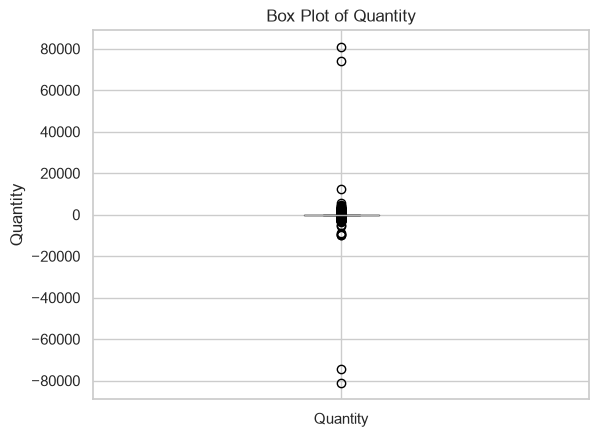

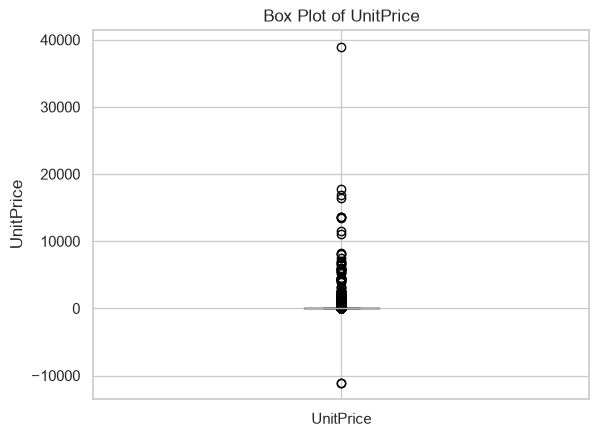

In [33]:
def box_plot(numeric_columns):
    for column in numeric_columns:
        df_1.boxplot(column=column)
        plt.title(f"Box Plot of {column}")
        plt.ylabel(column)
        plt.show()

# Call the function
box_plot(numeric_columns)

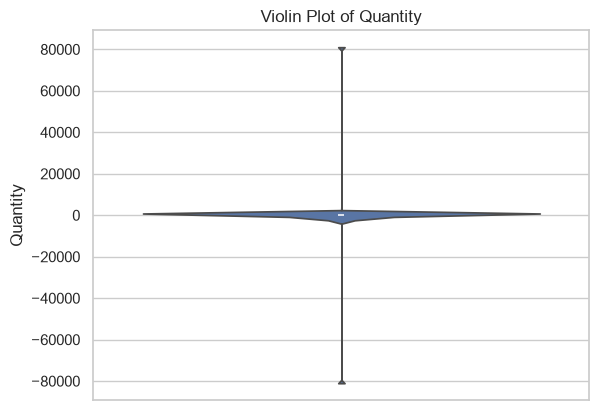

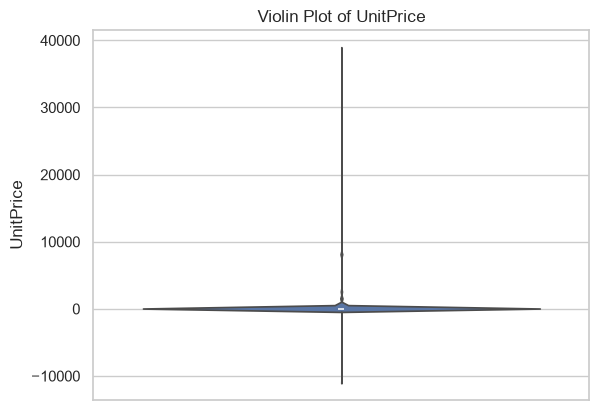

In [34]:
# Function to create violin plots for numeric columns
def violin_chart(numeric_columns):
    for column in numeric_columns:
        sns.violinplot(y=df_1[column])

        plt.title(f"Violin Plot of {column}")
        plt.ylabel(column)
        plt.show()

# Call the function
violin_chart(numeric_columns)